```bash
ns-render camera-path --load-config outputs/bouquet/neo/config.yml --camera-path-filename /workspace/Neo/data/bouquet/camera_paths/2024-07-14-23-44-39.json --output-path renders/bouquet --output-format images
```

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

In [2]:
def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)
    
def show_points(coords, labels, ax, marker_size=375):
    pos_points = coords[labels==1]
    neg_points = coords[labels==0]
    ax.scatter(pos_points[:, 0], pos_points[:, 1], color='green', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)
    ax.scatter(neg_points[:, 0], neg_points[:, 1], color='red', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)   
    
def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))    

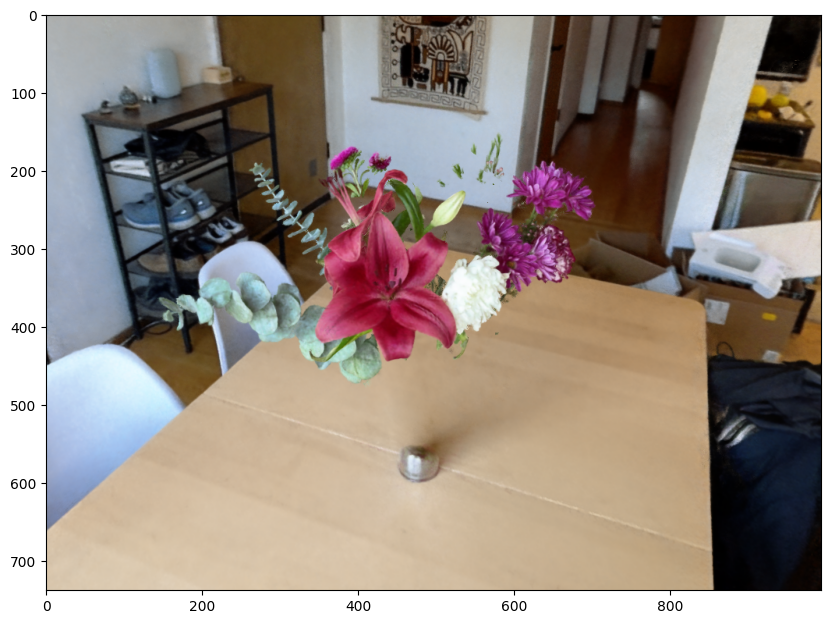

In [3]:
image = cv2.imread('/workspace/Neo/rgb_preview_23.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,10))
plt.imshow(image)
plt.axis('on')
plt.show()

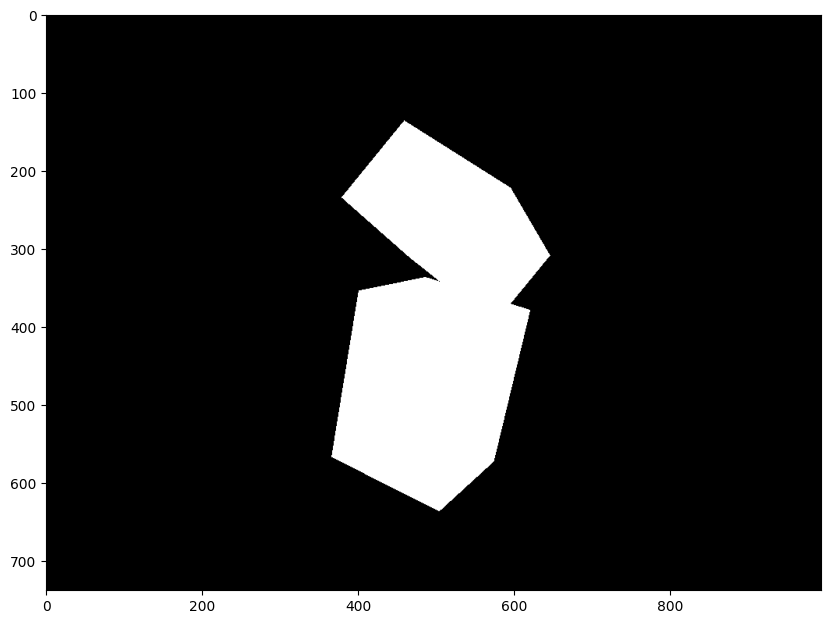

In [4]:
oryg_mask = cv2.imread('/workspace/Neo/train_0018.png')

plt.figure(figsize=(10,10))
plt.imshow(oryg_mask)
plt.axis('on')
plt.show()

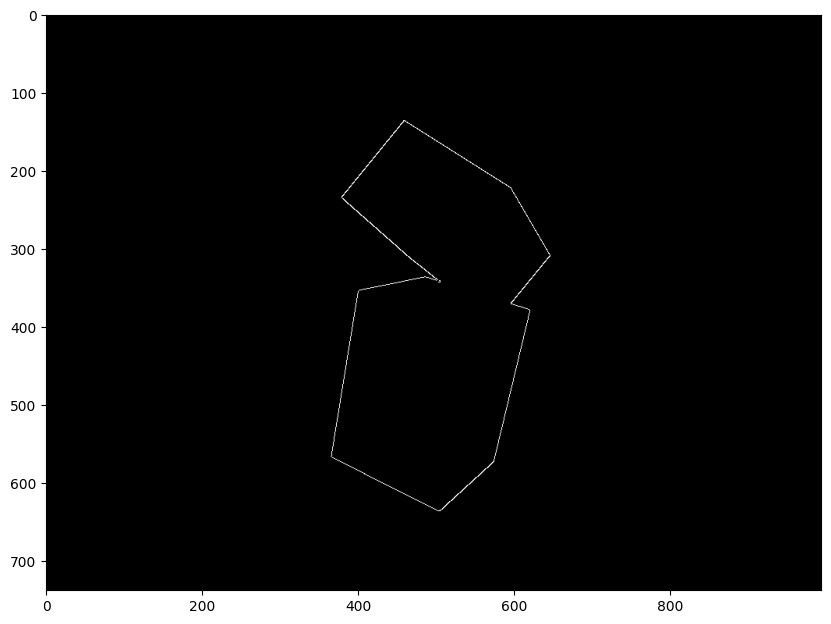

In [5]:
edges = cv2.Canny(oryg_mask, threshold1=100, threshold2=200)

plt.figure(figsize=(10,10))
plt.imshow(edges, cmap='gray')
plt.axis('on')
plt.show()

In [6]:
from segment_anything import sam_model_registry, SamPredictor

sam_checkpoint = "ckpts/sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

predictor = SamPredictor(sam)

In [7]:
predictor.set_image(image)

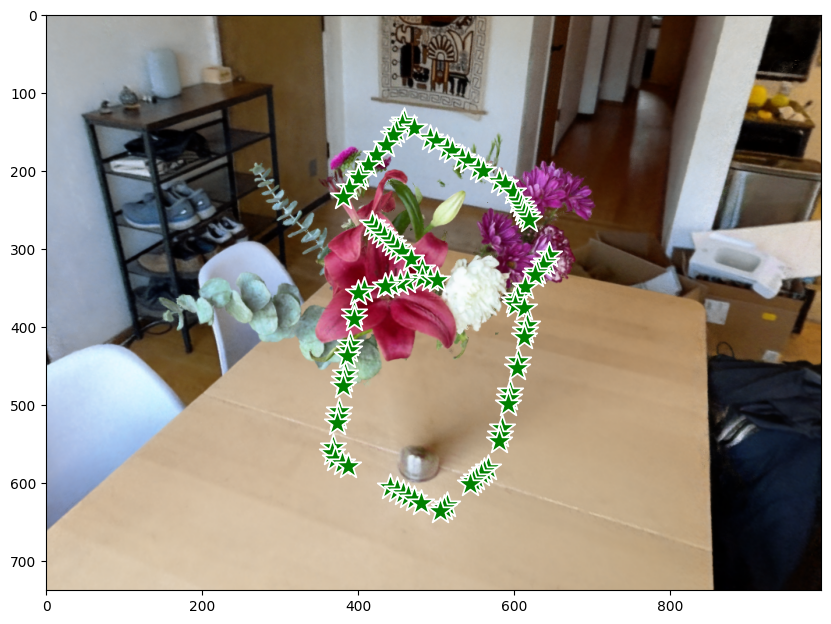

In [8]:
# input_point = np.array([[500, 500]])
# input_label = np.array([1])

input_points = np.array(np.where(edges == 255)).transpose()[:, ::-1]
indices = np.linspace(0, input_points.shape[0] - 1, 100, dtype=int)
input_points = input_points[indices]
input_labels = np.ones_like(input_points[:, 0])

plt.figure(figsize=(10,10))
plt.imshow(image)
show_points(input_points, input_labels, plt.gca())
plt.axis('on')
plt.show()  

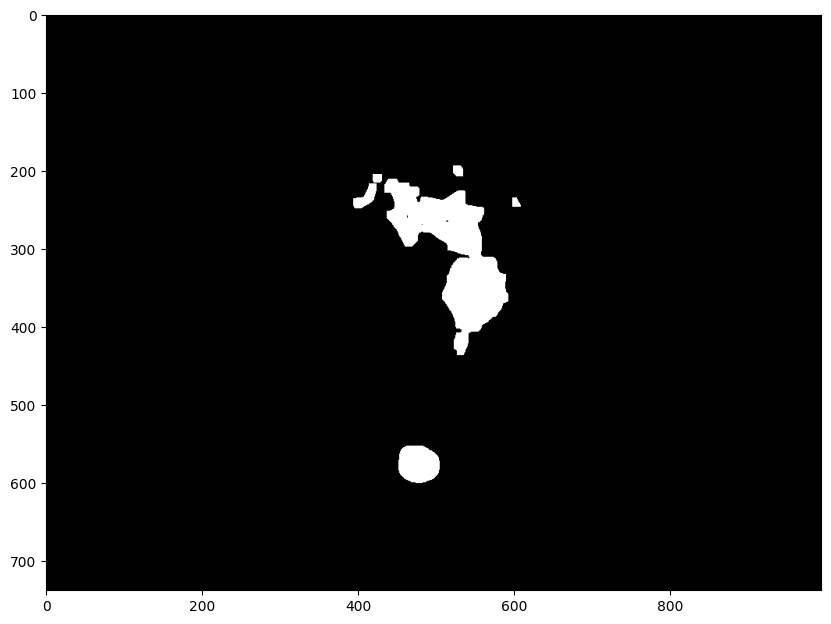

In [9]:
masks, scores, logits = [], [], []
for input_point, input_label in zip(input_points, input_labels):
    mask, score, logit = predictor.predict(
        point_coords=np.array([input_point]),
        point_labels=np.array([input_label]),
        multimask_output=False,
    )
    masks.append(mask[0])
    scores.append(score[0])
    logits.append(logit[0])

masks = np.array(masks)
scores = np.array(scores)
logits = np.array(logits)

sum_scores = scores.sum(0)[None, ...]
sum_masks = np.clip(masks.sum(0), 0, 1)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
sum_masks = cv2.morphologyEx((sum_masks * 255).astype(np.uint8), cv2.MORPH_CLOSE, kernel, iterations=2)[None, ...] / 255

refined_mask = np.logical_and(np.logical_xor(sum_masks[0], oryg_mask[..., 0]), oryg_mask[..., 0])

plt.figure(figsize=(10,10))
plt.imshow(refined_mask, cmap='gray')
plt.axis('on')
plt.show()


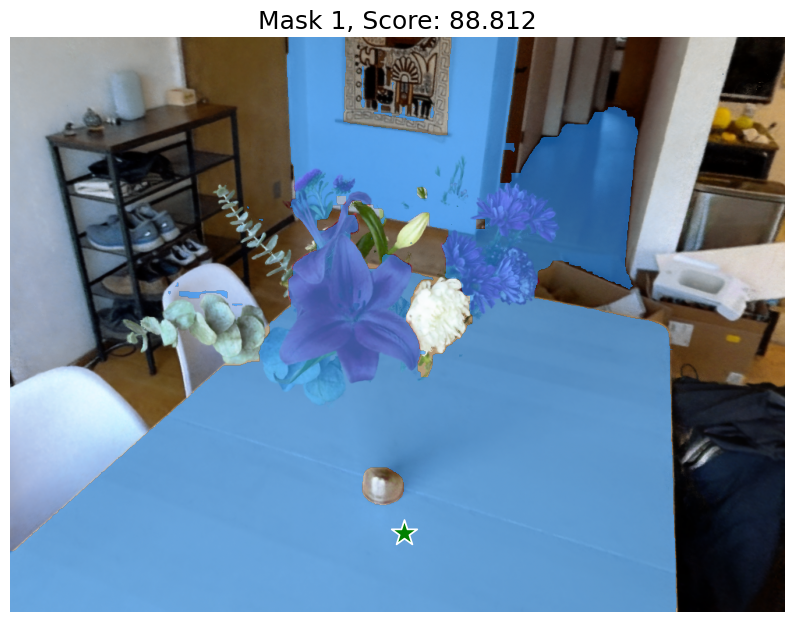

In [10]:
for i, (mask, score) in enumerate(zip(sum_masks, sum_scores)):
    plt.figure(figsize=(10,10))
    plt.imshow(image)
    show_mask(mask, plt.gca())
    show_points(input_point, input_label, plt.gca())
    plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
    plt.axis('off')
    plt.show()  